# How much does late delivery hurt review scores?

Every Olist order comes with a promised delivery date. "Late" means the order arrived after that date.
This notebook measures how review scores move with lateness, whether customers judge the actual
delivery time or the promise, and where late deliveries come from.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from sqlalchemy import create_engine, text

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SQL = ROOT / "sql"
IMAGES = ROOT / "images"

load_dotenv(ROOT / ".env")
engine = create_engine(os.environ["DATABASE_URL"])


def run_sql(name):
    return pd.read_sql((SQL / f"{name}.sql").read_text(), engine)


pd.read_sql("""
SELECT
    COUNT(*) AS delivered_orders,
    ROUND(AVG(CASE WHEN is_late THEN 1.0 ELSE 0 END) * 100, 2) AS late_pct,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY delivery_days) AS median_delivery_days,
    PERCENTILE_CONT(0.5) WITHIN GROUP (ORDER BY days_late) AS median_days_vs_promise,
    ROUND(AVG(CASE WHEN NOT is_late THEN review_score END), 2) AS avg_review_on_time,
    ROUND(AVG(CASE WHEN is_late THEN review_score END), 2) AS avg_review_late
FROM order_facts
WHERE order_status = 'delivered' AND is_late IS NOT NULL
""", engine).T.rename(columns={0: "value"})

,value
delivered_orders,96470.00
late_pct,6.77
median_delivery_days,10.20
median_days_vs_promise,-12.00
avg_review_on_time,4.29
avg_review_late,2.27


In [2]:
by_delay = run_sql("review_by_delay")
by_delay

,delivery_vs_promise,orders,pct_of_orders,avg_review,one_star_pct,five_star_pct
0,01. 15+ days early,34771,36.3,4.32,6.5,64.3
1,02. 8-14 days early,36158,37.7,4.31,6.4,63.0
2,03. 1-7 days early,17234,18.0,4.20,7.1,57.5
3,04. on the day,1280,1.3,4.03,8.5,50.6
4,05. 1-3 days late,1852,1.9,3.29,25.1,33.2
5,06. 4-7 days late,1748,1.8,2.10,58.6,14.1
6,07. 8-14 days late,1446,1.5,1.67,70.6,6.8
7,08. 15+ days late,1335,1.4,1.72,69.0,7.2


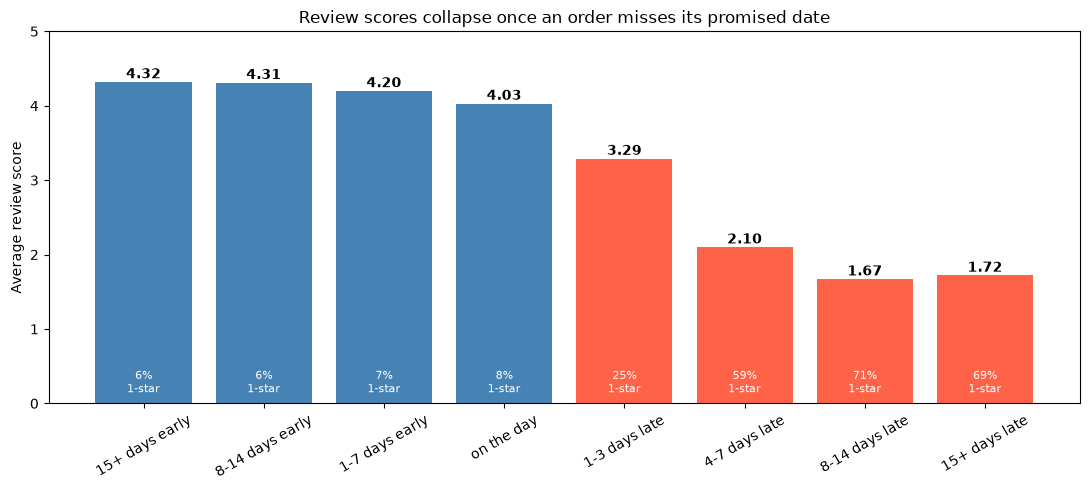

In [3]:
fig, ax = plt.subplots(figsize=(11, 5))
labels = by_delay["delivery_vs_promise"].str[4:]
colors = ["steelblue"] * 4 + ["tomato"] * 4
ax.bar(labels, by_delay["avg_review"], color=colors)
for i, (score, one_star) in enumerate(zip(by_delay["avg_review"], by_delay["one_star_pct"])):
    ax.text(i, score + 0.05, f"{score:.2f}", ha="center", fontweight="bold")
    ax.text(i, 0.15, f"{one_star:.0f}%\n1-star", ha="center", fontsize=8, color="white")
ax.set_ylim(0, 5)
ax.set_ylabel("Average review score")
ax.set_title("Review scores collapse once an order misses its promised date")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.savefig(IMAGES / "review_by_delay.png", dpi=150, bbox_inches="tight")
plt.show()

### Finding: the cliff
Orders that arrive early all score about the same (4.2-4.3). The drop starts the day the promise is
missed: 1-3 days late averages 3.29 with 25% one-star reviews, 4-7 days late averages 2.10, and past a
week late about **70% of reviews are 1-star**. Olist pads its promised dates heavily (the median order
arrives 12 days early), which is why only 6.8% of deliveries are late at all.

### Do customers judge the wait, or the promise?
Cross actual delivery time with whether the order beat its promised date.

In [4]:
promise = pd.read_sql("""
SELECT
    CASE
        WHEN delivery_days < 7 THEN '1. under 7 days'
        WHEN delivery_days < 14 THEN '2. 7-13 days'
        WHEN delivery_days < 21 THEN '3. 14-20 days'
        WHEN delivery_days < 30 THEN '4. 21-29 days'
        ELSE '5. 30+ days'
    END AS actual_wait,
    CASE WHEN is_late THEN 'late' ELSE 'on time' END AS vs_promise,
    COUNT(*) AS orders,
    ROUND(AVG(review_score), 2) AS avg_review
FROM order_facts
WHERE order_status = 'delivered' AND is_late IS NOT NULL AND review_score IS NOT NULL
GROUP BY 1, 2
ORDER BY 1, 2
""", engine)
promise.pivot(index="actual_wait", columns="vs_promise", values=["avg_review", "orders"])

avg_review          orders         
vs_promise            late on time    late  on time
actual_wait                                        
1. under 7 days       3.98    4.42    58.0  25386.0
2. 7-13 days          3.36    4.32   307.0  39885.0
3. 14-20 days         2.91    4.18   528.0  17248.0
4. 21-29 days         2.59    3.96  1997.0   5957.0
5. 30+ days           1.86    3.67  3491.0    967.0

### Finding: expectations
**Customers judge the promise, not the wait.** For the same 7-13 day wait, on-time orders average 4.32
and late ones 3.36. An order that took 30+ days but arrived on time (3.67) scores better than a late order
that took 21-29 days (2.59). Speed matters a little, but missing the promised date matters far more.
That makes generous delivery estimates a deliberate and effective strategy, and it means tightening them
to look faster would be risky.

### How much of the bad-review problem is lateness?

In [5]:
pd.read_sql("""
WITH delivered AS (
    SELECT is_late, review_score
    FROM order_facts
    WHERE order_status = 'delivered' AND is_late IS NOT NULL AND review_score IS NOT NULL
)
SELECT
    ROUND(AVG(CASE WHEN is_late THEN 1.0 ELSE 0 END) * 100, 1) AS late_share_of_orders_pct,
    ROUND(SUM(CASE WHEN is_late AND review_score <= 2 THEN 1 ELSE 0 END) * 100.0
          / SUM(CASE WHEN review_score <= 2 THEN 1 ELSE 0 END), 1) AS late_share_of_1_2_star_pct,
    ROUND(AVG(review_score), 3) AS avg_review_actual,
    ROUND(AVG(CASE WHEN is_late THEN (SELECT AVG(review_score) FROM delivered WHERE NOT is_late)
                   ELSE review_score END), 3) AS avg_review_if_never_late
FROM delivered
""", engine).T.rename(columns={0: "value"})

,value
late_share_of_orders_pct,6.700
late_share_of_1_2_star_pct,32.500
avg_review_actual,4.156
avg_review_if_never_late,4.290


### Where does lateness come from?

In [6]:
by_state = pd.read_sql("""
SELECT
    customer_state,
    COUNT(*) AS delivered_orders,
    ROUND(AVG(CASE WHEN is_late THEN 1.0 ELSE 0 END) * 100, 1) AS late_pct,
    ROUND(AVG(delivery_days), 1) AS avg_delivery_days,
    ROUND(AVG(review_score), 2) AS avg_review
FROM order_facts
WHERE order_status = 'delivered' AND is_late IS NOT NULL
GROUP BY customer_state
HAVING COUNT(*) >= 300
ORDER BY late_pct DESC
""", engine)
by_state

,customer_state,delivered_orders,late_pct,avg_delivery_days,avg_review
0,AL,397,21.4,24.5,3.85
1,MA,717,17.4,21.6,3.83
2,SE,335,15.2,21.5,3.91
3,PI,476,13.9,19.5,3.99
4,CE,1279,13.8,21.3,3.94
5,BA,3256,12.2,19.3,3.93
6,RJ,12350,12.1,15.3,3.97
7,PA,946,11.2,23.8,3.91
8,ES,1995,10.7,15.8,4.08
9,PB,517,10.4,20.4,4.08


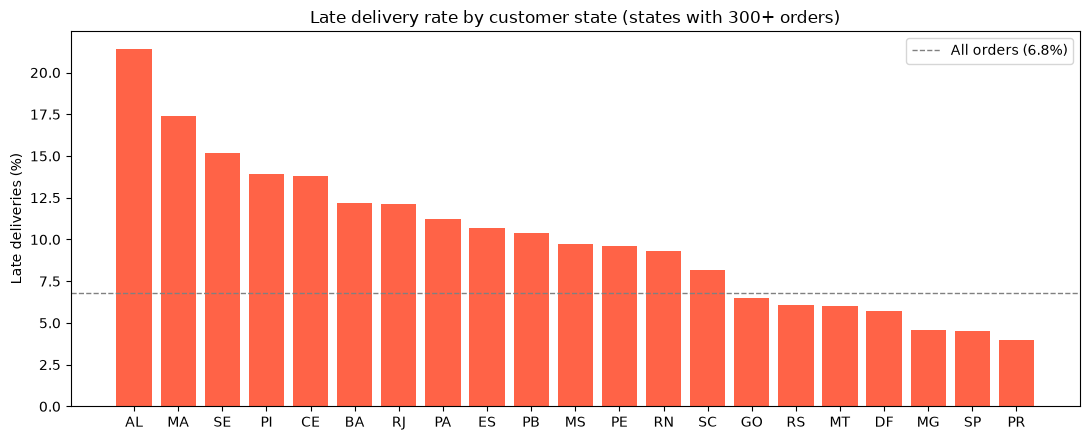

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(by_state["customer_state"], by_state["late_pct"], color="tomato")
ax.axhline(6.8, color="gray", linestyle="--", linewidth=1, label="All orders (6.8%)")
ax.set_ylabel("Late deliveries (%)")
ax.set_title("Late delivery rate by customer state (states with 300+ orders)")
ax.legend()
plt.tight_layout()
plt.savefig(IMAGES / "late_by_state.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
run_sql("late_sellers_pareto")

,seller_rank,top_pct_of_sellers,pct_of_late_deliveries,pct_of_all_deliveries
0,10,0.3,15.7,13.7
1,25,0.8,27.5,22.9
2,50,1.7,38.1,31.8
3,100,3.4,50.4,41.7
4,155,5.2,59.7,50.3
5,310,10.5,74.9,63.6
6,500,16.9,84.7,73.4


In [9]:
pd.read_sql(text("""
WITH seller_stats AS (
    SELECT
        main_seller_id,
        COUNT(*) AS delivered_orders,
        AVG(CASE WHEN is_late THEN 1.0 ELSE 0 END) AS late_rate,
        AVG(review_score) AS avg_review
    FROM order_facts
    WHERE order_status = 'delivered' AND is_late IS NOT NULL
    GROUP BY main_seller_id
    HAVING COUNT(*) >= 50
)
SELECT
    CASE
        WHEN late_rate < 0.05 THEN '1. under 5% late'
        WHEN late_rate < 0.10 THEN '2. 5-10% late'
        WHEN late_rate < 0.15 THEN '3. 10-15% late'
        ELSE '4. 15%+ late'
    END AS seller_late_rate,
    COUNT(*) AS sellers,
    SUM(delivered_orders) AS orders,
    ROUND(AVG(avg_review), 2) AS avg_review
FROM seller_stats
GROUP BY 1
ORDER BY 1
"""), engine)

,seller_late_rate,sellers,orders,avg_review
0,1. under 5% late,175,23187.0,4.28
1,2. 5-10% late,163,38778.0,4.16
2,3. 10-15% late,62,8683.0,3.99
3,4. 15%+ late,18,2010.0,3.66


### Findings
- **Late orders are 6.7% of deliveries but 32.5% of all 1-2 star reviews.** If no order had been late,
  the average review would rise from 4.16 to 4.29.
- **Lateness is mostly geographic.** Customers in the north-east wait longest and are most often let down:
  Alagoas 21.4% late, Maranhão 17.4%, Sergipe 15.2%, vs. São Paulo 4.5% and Paraná 4.0%. Rio de Janeiro
  stands out among big states at 12.1%.
- **It is only mildly concentrated in sellers.** The 100 sellers with the most late deliveries (3.4% of
  sellers) account for 50% of late deliveries, but they also handle 42% of all deliveries. Still, among
  sellers with 50+ orders, the 18 that are late more than 15% of the time average 3.66 stars vs. 4.28 for
  sellers under 5%.

**Answer:** late delivery costs about 2 points of review score per late order (4.29 to 2.27), and once an
order is a week late most customers give 1 star. The fix is to keep promises rather than speed up:
pad estimates more for north-eastern states and Rio, and flag the small group of chronically late sellers.